In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('svm.csv')
df.head()

,Applicant_ID,Age,Annual_Income,Credit_Score,Employment_Years,Debt_to_Income,Loan_Amount,Existing_Loans,Monthly_Expenses,Employment_Type,Education,Property_Type,Loan_Purpose,Loan_Approved
0,L001,24,38000,642,2,0.42,180000,1,22000,Salaried,Graduate,Rented,Education,No
1,L002,31,72000,735,7,0.28,350000,0,30000,Salaried,Postgraduate,Owned,Home,Yes
2,L003,45,56000,615,12,0.51,420000,3,38000,Self_Employed,Graduate,Owned,Business,No
3,L004,28,48000,690,4,0.35,250000,1,26000,Salaried,Graduate,Rented,Vehicle,Yes
4,L005,52,95000,778,20,0.22,600000,0,42000,Business,Postgraduate,Owned,Home,Yes


In [3]:
df.isnull().sum()

Applicant_ID        0
Age                 0
Annual_Income       0
Credit_Score        0
Employment_Years    0
Debt_to_Income      0
Loan_Amount         0
Existing_Loans      0
Monthly_Expenses    0
Employment_Type     0
Education           0
Property_Type       0
Loan_Purpose        0
Loan_Approved       0
dtype: int64

In [5]:
df.drop('Applicant_ID',axis=1,inplace=True)

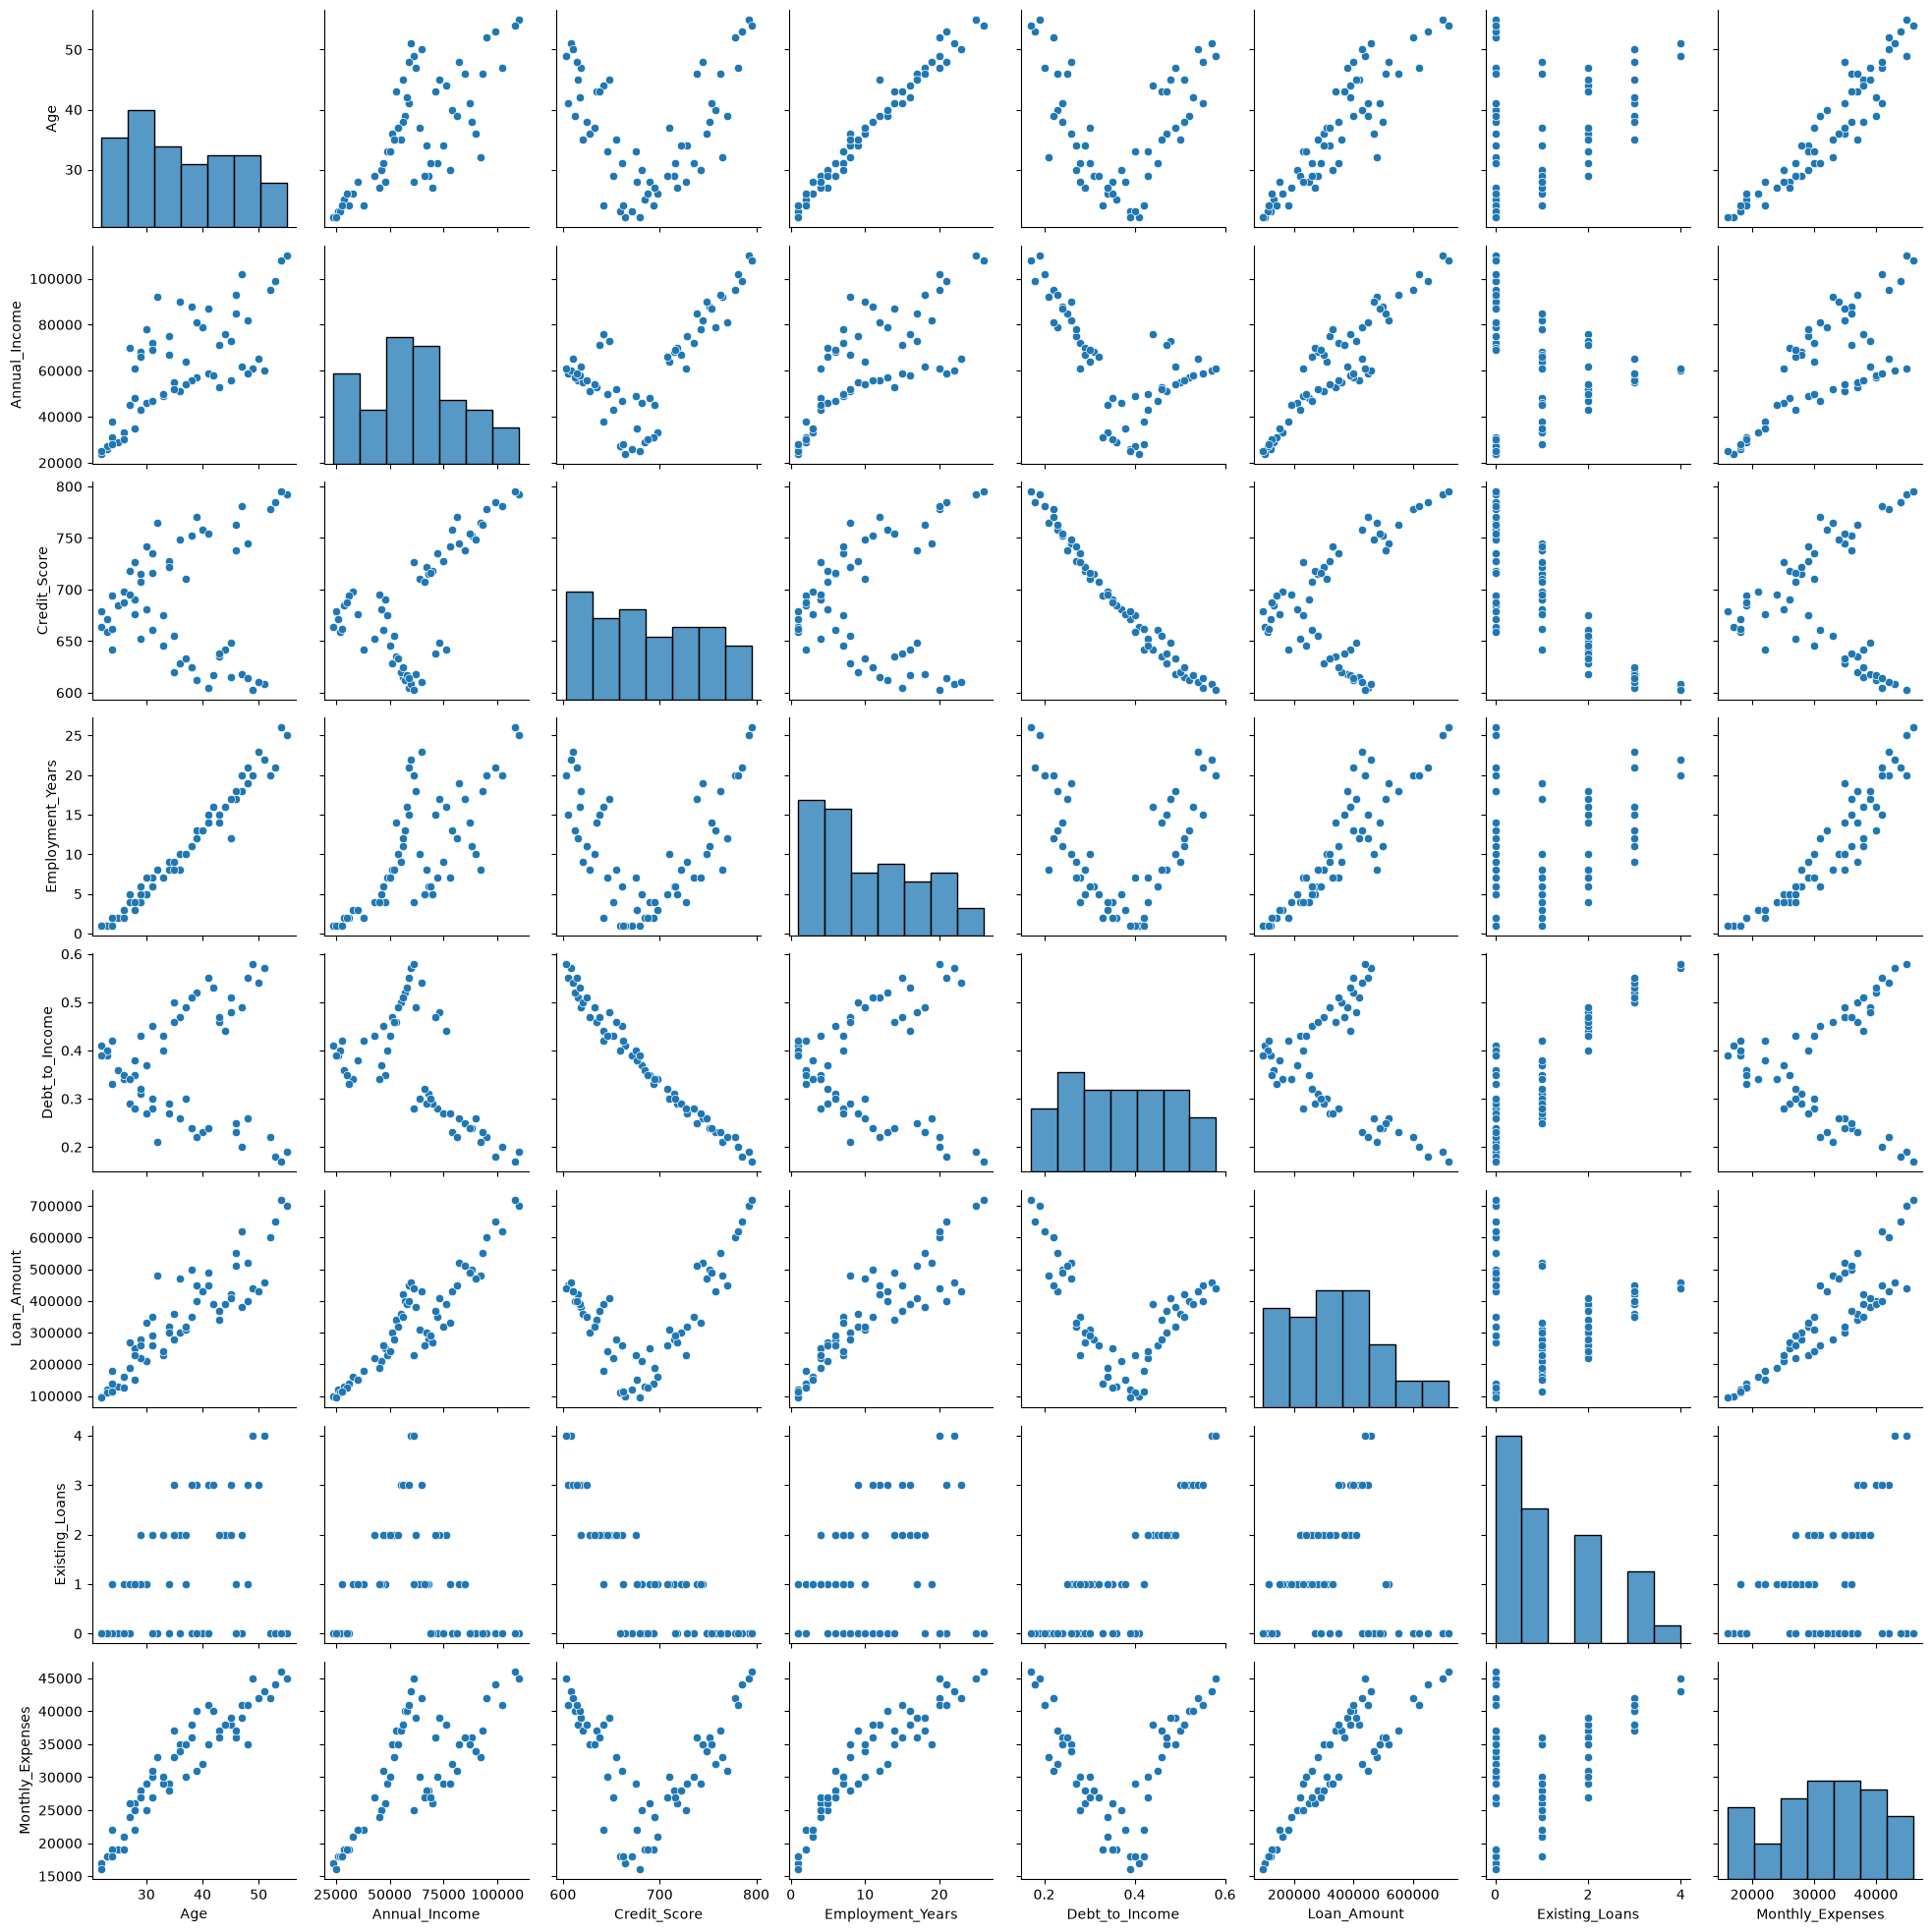

In [ ]:
sns.pairplot(df)

plt.show()

In [8]:
X=df.drop('Employment_Type',axis=1)
y=df['Employment_Type']

In [9]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=0)

In [10]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

num_features=X_train.select_dtypes(exclude=['object']).columns.tolist()
cat_features=X_train.select_dtypes(include=['object']).columns.tolist()

preprocessor=ColumnTransformer(
    transformers=[
        ('num',StandardScaler(),num_features),
        ('cat',OneHotEncoder(handle_unknown='ignore'),cat_features)
    ]
)

X_train_preprocessed=preprocessor.fit_transform(X_train)
X_test_preprocessed=preprocessor.transform(X_test)

C:\Users\Hrishikesh Kulkarni\AppData\Local\Temp\ipykernel_47532\312493611.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features=X_train.select_dtypes(include=['object']).columns.tolist()


In [11]:
from sklearn.svm import SVC

model=SVC()
model.fit(X_train_preprocessed,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [12]:
y_pred=model.predict(X_test_preprocessed)
y_pred

array(['Salaried', 'Business', 'Business', 'Salaried', 'Student',
       'Salaried', 'Salaried', 'Self_Employed', 'Student', 'Student',
       'Business', 'Salaried', 'Business', 'Business', 'Student',
       'Self_Employed', 'Salaried', 'Salaried'], dtype=object)

In [15]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

print(accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

0.9444444444444444
               precision    recall  f1-score   support

     Business       1.00      1.00      1.00         5
     Salaried       0.86      1.00      0.92         6
Self_Employed       1.00      0.67      0.80         3
      Student       1.00      1.00      1.00         4

     accuracy                           0.94        18
    macro avg       0.96      0.92      0.93        18
 weighted avg       0.95      0.94      0.94        18

[[5 0 0 0]
 [0 6 0 0]
 [0 1 2 0]
 [0 0 0 4]]


In [16]:
import pickle

pickle.dump(model,open('model.pkl','wb'))
print('Model saved')

Model saved
